# Technology-trade global development and diagnostics

Global 2004–2024 review using each reporter-year's native HS classification. This notebook consumes production outputs only. It does not collect data or rebuild the panel.

Score convention: positive values indicate stronger US orientation, negative values indicate stronger China orientation, and zero indicates balance.


In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 200)
pd.set_option("display.max_colwidth", 120)


def find_repository_root():
    for path in [Path.cwd(), *Path.cwd().parents]:
        if (path / "requirements.txt").exists() and (path / "src").exists():
            return path
    raise FileNotFoundError("Repository root not found")


ROOT = find_repository_root()
PROCESSED = ROOT / "data" / "processed"
TABLES = ROOT / "outputs" / "tables" / "technology"
REFERENCE = ROOT / "data" / "reference" / "unctad_ict_goods_hs6.csv"
ROOT


PosixPath('.')

## 1. Load collection and production outputs

The collection manifest records one row per available reporter-year and anchor. The coverage table retains the full eligible universe, including unavailable reporter-years.


In [2]:
paths = {
    "manifest": TABLES / "technology_collection_manifest.csv",
    "reporter_year_coverage": TABLES / "technology_reporter_year_coverage.csv",
    "panel": PROCESSED / "technology_trade_country_year.csv",
    "sensitivity": TABLES / "technology_basket_sensitivity.csv",
    "category": TABLES / "technology_category_composition.csv",
    "product_coverage": TABLES / "technology_product_coverage.csv",
    "unmatched": TABLES / "technology_unmatched_classification_rows.csv",
    "summary": TABLES / "technology_summary.json",
}

missing_files = [str(path.relative_to(ROOT)) for path in paths.values() if not path.exists()]
if missing_files:
    raise FileNotFoundError("Missing required production outputs:\n" + "\n".join(missing_files))

manifest = pd.read_csv(paths["manifest"])
reporter_year_coverage = pd.read_csv(paths["reporter_year_coverage"])
panel = pd.read_csv(paths["panel"])
sensitivity = pd.read_csv(paths["sensitivity"])
category = pd.read_csv(paths["category"])
product_coverage = pd.read_csv(paths["product_coverage"])
unmatched = pd.read_csv(paths["unmatched"])
summary = json.loads(paths["summary"].read_text())

print("Manifest rows:", len(manifest))
print("Coverage rows:", len(reporter_year_coverage))
print("Baseline panel rows:", len(panel))
print("Sensitivity rows:", len(sensitivity))
print("Category rows:", len(category))
print("Product-coverage rows:", len(product_coverage))


Manifest rows: 6720
Coverage rows: 4032
Baseline panel rows: 3360
Sensitivity rows: 26880
Category rows: 100800
Product-coverage rows: 26880


## 2. End-to-end production integrity gates

These checks derive expectations from the coverage table. They contain no fixed pilot-country or pilot-row assumptions. A mismatch here means the builder output is not aligned with the global collection and should be corrected before interpretation.


In [3]:
available_reporter_years = (
    reporter_year_coverage.loc[
        reporter_year_coverage["technology_trade_status"].eq("available"),
        ["reporter_iso", "year"],
    ]
    .drop_duplicates()
    .sort_values(["reporter_iso", "year"])
)

expected_manifest_rows = 2 * len(available_reporter_years)
manifest_reporter_years = manifest[["reporter_iso", "year"]].drop_duplicates()
panel_reporter_years = panel[["reporter_iso", "year"]].drop_duplicates()

integrity = pd.Series({
    "available_reporter_years": len(available_reporter_years),
    "expected_manifest_rows": expected_manifest_rows,
    "observed_manifest_rows": len(manifest),
    "expected_panel_rows": len(available_reporter_years),
    "observed_panel_rows": len(panel),
    "manifest_errors": manifest["status"].astype(str).str.startswith("error").sum(),
    "manifest_duplicate_anchor_rows": manifest.duplicated(["reporter_iso", "year", "anchor_iso3"]).sum(),
    "coverage_duplicate_reporter_years": reporter_year_coverage.duplicated(["reporter_iso", "year"]).sum(),
    "panel_duplicate_reporter_years": panel.duplicated(["reporter_iso", "year"]).sum(),
})
display(integrity.to_frame("value"))

problems = []
if len(manifest) != expected_manifest_rows:
    problems.append(f"manifest rows {len(manifest):,} != expected {expected_manifest_rows:,}")
if len(panel) != len(available_reporter_years):
    problems.append(f"panel rows {len(panel):,} != available reporter-years {len(available_reporter_years):,}")
if set(map(tuple, manifest_reporter_years.to_numpy())) != set(map(tuple, available_reporter_years.to_numpy())):
    problems.append("manifest reporter-years do not equal available coverage reporter-years")
if set(map(tuple, panel_reporter_years.to_numpy())) != set(map(tuple, available_reporter_years.to_numpy())):
    problems.append("panel reporter-years do not equal available coverage reporter-years")
if integrity["manifest_errors"]:
    problems.append("manifest contains request errors")
if integrity[["manifest_duplicate_anchor_rows", "coverage_duplicate_reporter_years", "panel_duplicate_reporter_years"]].sum():
    problems.append("duplicate keys found in production outputs")
if set(manifest["anchor_iso3"].dropna()) != {"CHN", "USA"}:
    problems.append("manifest anchors are not exactly CHN and USA")
if not manifest["expected_classification"].isin(["H0", "H1", "H2", "H3", "H4", "H5", "H6"]).all():
    problems.append("manifest contains an unsupported classification")
if manifest["year"].min() != 2004 or manifest["year"].max() != 2024:
    problems.append("manifest does not span 2004–2024")

if problems:
    raise RuntimeError("Global production integrity failed:\n- " + "\n- ".join(problems))

print("Global collection, coverage and processed panel are aligned.")


,value
available_reporter_years,3360
expected_manifest_rows,6720
observed_manifest_rows,6720
expected_panel_rows,3360
observed_panel_rows,3360
manifest_errors,0
manifest_duplicate_anchor_rows,0
coverage_duplicate_reporter_years,0
panel_duplicate_reporter_years,0


Global collection, coverage and processed panel are aligned.


## 3. Classification matching and score-domain checks


In [4]:
assert summary["raw_rows"] == summary["standardised_rows"]
assert summary["matched_classification_rows"] == summary["raw_rows"]
assert summary["unmatched_classification_rows"] == 0
assert summary["unmatched_trade_value_usd"] == 0
assert unmatched.empty

score_columns = [
    "gross_orientation_score",
    "dva_adjusted_orientation_score",
    "equal_category_gross_score",
    "equal_category_dva_score",
]
for column in score_columns:
    assert sensitivity[column].dropna().between(-1, 1).all(), column

print("Classification matching and score-domain checks passed.")


Classification matching and score-domain checks passed.


## 4. Reporter-year availability and native HS revisions


In [5]:
coverage_summary = (
    reporter_year_coverage.groupby(["year", "technology_trade_status"])
    .size()
    .rename("reporter_years")
    .reset_index()
)
display(coverage_summary.tail(30))

a = manifest[["reporter_iso", "year", "expected_classification", "hs_revision"]].drop_duplicates()
revision_summary = (
    a.groupby(["year", "expected_classification", "hs_revision"])
    .size()
    .rename("reporters")
    .reset_index()
)
display(revision_summary)

assert a.duplicated(["reporter_iso", "year"]).sum() == 0


,year,technology_trade_status,reporter_years
33,2015,available,162
34,2015,unavailable_missing_native_classification,21
35,2015,unavailable_missing_reporter_code,9
36,2016,available,166
37,2016,unavailable_missing_native_classification,17
38,2016,unavailable_missing_reporter_code,9
39,2017,available,169
40,2017,unavailable_missing_native_classification,14
41,2017,unavailable_missing_reporter_code,9
42,2018,available,166


,year,expected_classification,hs_revision,reporters
0,2004,H0,HS1992,9
1,2004,H1,HS1996,35
2,2004,H2,HS2002,115
3,2005,H0,HS1992,7
4,2005,H1,HS1996,24
5,2005,H2,HS2002,126
6,2006,H0,HS1992,6
7,2006,H1,HS1996,17
8,2006,H2,HS2002,137
9,2007,H0,HS1992,5


## 5. Returned-product coverage and legitimate empty responses


In [6]:
status_summary = manifest["status"].value_counts(dropna=False).rename_axis("status").reset_index(name="rows")
display(status_summary)

returned_summary = (
    manifest.groupby(["year", "hs_revision", "anchor_iso3"])
    .agg(
        reporter_years=("reporter_iso", "size"),
        empty_responses=("status", lambda x: x.eq("downloaded_empty").sum()),
        median_hs6_returned=("returned_hs6", "median"),
        mean_hs6_returned=("returned_hs6", "mean"),
    )
    .reset_index()
)
display(returned_summary)

empty_cases = manifest.loc[
    manifest["status"].eq("downloaded_empty"),
    ["reporter_iso", "year", "anchor_iso3", "expected_classification", "hs_revision"],
]
print("Legitimate empty reporter-anchor responses:", len(empty_cases))


,status,rows
0,downloaded,6438
1,cached,168
2,downloaded_empty,114


,year,hs_revision,anchor_iso3,reporter_years,empty_responses,median_hs6_returned,mean_hs6_returned
0,2004,HS1992,CHN,9,0,17.0,25.222222
1,2004,HS1992,USA,9,1,23.0,26.000000
2,2004,HS1996,CHN,35,3,43.0,44.600000
3,2004,HS1996,USA,35,0,59.0,54.942857
4,2004,HS2002,CHN,115,4,81.0,74.486957
5,2004,HS2002,USA,115,4,79.0,74.982609
6,2005,HS1992,CHN,7,0,25.0,31.428571
7,2005,HS1992,USA,7,0,19.0,26.428571
8,2005,HS1996,CHN,24,1,44.0,45.250000
9,2005,HS1996,USA,24,1,64.0,54.333333


Legitimate empty reporter-anchor responses: 114


## 6. Baseline global score distribution through time

Global distributions are more informative than plotting approximately 183 country trajectories on one chart.


,year,countries,median,q25,q75,minimum,maximum
0,2004,155,0.168438,-0.153835,0.692835,-1.000000,1.000000
1,2005,154,-0.032067,-0.371462,0.521380,-0.985684,1.000000
2,2006,158,-0.135261,-0.449871,0.465768,-1.000000,1.000000
3,2007,159,-0.246323,-0.640778,0.231327,-1.000000,1.000000
4,2008,157,-0.499496,-0.689847,-0.006682,-1.000000,1.000000
5,2009,157,-0.561443,-0.760492,-0.082078,-1.000000,1.000000
6,2010,162,-0.624072,-0.837737,-0.173598,-1.000000,1.000000
7,2011,159,-0.659837,-0.800674,-0.224738,-1.000000,0.999604
8,2012,157,-0.660744,-0.830471,-0.332684,-1.000000,0.998178
9,2013,160,-0.674317,-0.831674,-0.345903,-1.000000,0.988200


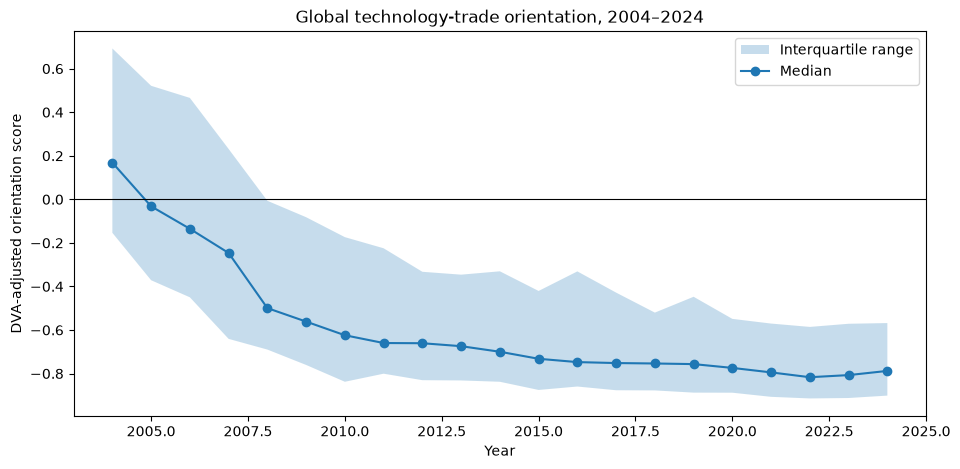

In [7]:
annual_scores = (
    panel.groupby("year")["dva_adjusted_orientation_score"]
    .agg(
        countries="count",
        median="median",
        q25=lambda x: x.quantile(0.25),
        q75=lambda x: x.quantile(0.75),
        minimum="min",
        maximum="max",
    )
    .reset_index()
)
display(annual_scores)

fig, ax = plt.subplots(figsize=(11, 5))
ax.fill_between(annual_scores["year"], annual_scores["q25"], annual_scores["q75"], alpha=0.25, label="Interquartile range")
ax.plot(annual_scores["year"], annual_scores["median"], marker="o", label="Median")
ax.axhline(0, color="black", linewidth=0.8)
ax.set(title="Global technology-trade orientation, 2004–2024", xlabel="Year", ylabel="DVA-adjusted orientation score")
ax.legend()
plt.show()


## 7. Gross versus TiVA-adjusted orientation


In [8]:
adjustment = panel[["reporter_iso", "year", "gross_orientation_score", "dva_adjusted_orientation_score"]].copy()
adjustment["adjustment"] = adjustment["dva_adjusted_orientation_score"] - adjustment["gross_orientation_score"]
display(adjustment["adjustment"].describe().to_frame("value"))
display(adjustment.reindex(adjustment["adjustment"].abs().sort_values(ascending=False).index).head(20))


,value
count,3322.000000
mean,0.077582
std,0.056561
min,0.000000
25%,0.030923
50%,0.065396
75%,0.116053
max,0.227999


,reporter_iso,year,gross_orientation_score,dva_adjusted_orientation_score,adjustment
1434,IRL,2004,-0.114003,0.113996,0.227999
1123,GAB,2004,-0.117062,0.110935,0.227997
379,BIH,2004,-0.118143,0.109852,0.227995
967,EGY,2004,-0.120727,0.107261,0.227988
1479,ISL,2004,-0.101986,0.125979,0.227966
1563,JOR,2004,-0.137653,0.090216,0.227869
2385,NZL,2004,-0.088128,0.139718,0.227845
1521,ITA,2004,-0.139868,0.087976,0.227843
219,BDI,2004,-0.142583,0.085226,0.227809
95,ARG,2004,-0.083064,0.144715,0.227779


## 8. Basket sensitivity and pooled versus equal-category measures


In [9]:
comparison = panel[[
    "reporter_iso",
    "year",
    "dva_adjusted_orientation_score",
    "equal_category_dva_score",
]].copy()

comparison["both_scores_observed"] = comparison[
    ["dva_adjusted_orientation_score", "equal_category_dva_score"]
].notna().all(axis=1)

comparison["direction_disagreement"] = False
comparison.loc[
    comparison["both_scores_observed"],
    "direction_disagreement",
] = (
    np.sign(
        comparison.loc[
            comparison["both_scores_observed"],
            "dva_adjusted_orientation_score",
        ]
    )
    != np.sign(
        comparison.loc[
            comparison["both_scores_observed"],
            "equal_category_dva_score",
        ]
    )
)

valid_comparisons = comparison.loc[
    comparison["both_scores_observed"]
].copy()

disagreement_count = int(
    valid_comparisons["direction_disagreement"].sum()
)

print("Reporter-years with both scores observed:", len(valid_comparisons))
print("Valid pooled/equal-category direction disagreements:", disagreement_count)
print(
    "Disagreement rate:",
    disagreement_count / len(valid_comparisons)
    if len(valid_comparisons)
    else np.nan,
)

display(
    valid_comparisons.loc[
        valid_comparisons["direction_disagreement"]
    ].head(25)
)


Reporter-years with both scores observed: 3322
Valid pooled/equal-category direction disagreements: 225
Disagreement rate: 0.06773028296207104


,reporter_iso,year,dva_adjusted_orientation_score,equal_category_dva_score,both_scores_observed,direction_disagreement
15,AGO,2007,-0.138905,0.160255,True,True
18,AGO,2010,-0.302608,0.146008,True,True
21,AGO,2013,-0.179240,0.084705,True,True
35,ALB,2006,-0.340391,0.005703,True,True
156,AUS,2004,-0.069707,0.216160,True,True
157,AUS,2005,-0.242295,0.084871,True,True
158,AUS,2006,-0.216906,0.053119,True,True
159,AUS,2007,-0.333366,0.030862,True,True
178,AUT,2005,-0.144196,0.082004,True,True
180,AUT,2007,-0.062816,0.096221,True,True


## 9. Category composition and score drivers


ict_category_code,ICT01,ICT02,ICT04,ICT05
year,,,,
2020,0.361035,0.396504,0.183270,0.059191
2021,0.361317,0.376703,0.197527,0.064453
2022,0.356573,0.362290,0.236596,0.044541
2023,0.318396,0.410168,0.232084,0.039352
2024,0.354082,0.372047,0.233272,0.040599


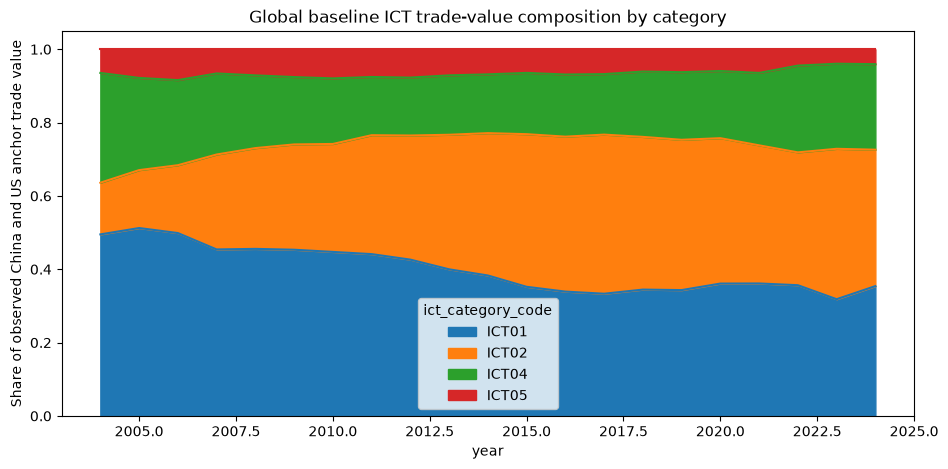

In [10]:
baseline_category = category.loc[
    category["basket"].eq("include_baseline")
].copy()

category_year = (
    baseline_category.groupby(
        ["year", "ict_category_code"]
    )["category_imports_usd"]
    .sum()
    .unstack("ict_category_code")
    .fillna(0)
)

category_share = category_year.div(
    category_year.sum(axis=1).replace(0, pd.NA),
    axis=0,
)

display(category_share.tail())

category_share.plot.area(
    figsize=(11, 5),
    title="Global baseline ICT trade-value composition by category",
)
plt.ylabel("Share of observed China and US anchor trade value")
plt.show()


## 10. Volatility and largest annual movements


In [11]:
panel_revision = (
    manifest[["reporter_iso", "year", "hs_revision"]]
    .drop_duplicates()
)

moves = (
    panel.sort_values(["reporter_iso", "year"])
    [["reporter_iso", "year", "dva_adjusted_orientation_score"]]
    .merge(
        panel_revision,
        on=["reporter_iso", "year"],
        how="left",
        validate="one_to_one",
    )
    .sort_values(["reporter_iso", "year"])
)

assert moves["hs_revision"].notna().all()

moves["previous_year"] = moves.groupby("reporter_iso")["year"].shift()
moves["year_gap"] = moves["year"] - moves["previous_year"]
moves["previous_score"] = moves.groupby("reporter_iso")[
    "dva_adjusted_orientation_score"
].shift()

moves["annual_change"] = (
    moves["dva_adjusted_orientation_score"]
    - moves["previous_score"]
).where(moves["year_gap"].eq(1))

moves["absolute_change"] = moves["annual_change"].abs()

print(
    "Consecutive-year changes:",
    int(moves["annual_change"].notna().sum()),
)
print(
    "Non-consecutive comparisons excluded:",
    int(moves["year_gap"].gt(1).sum()),
)

display(moves.nlargest(30, "absolute_change"))

volatility = (
    moves.groupby("reporter_iso")["annual_change"]
    .agg(
        observations="count",
        mean_absolute_change=lambda x: x.abs().mean(),
        standard_deviation="std",
    )
    .sort_values("mean_absolute_change", ascending=False)
)

display(volatility.head(30))


Consecutive-year changes: 3092
Non-consecutive comparisons excluded: 40


,reporter_iso,year,dva_adjusted_orientation_score,hs_revision,previous_year,year_gap,previous_score,annual_change,absolute_change
2923,SWZ,2007,1.000000,HS1996,2006.0,1.0,-1.000000,2.000000,2.000000
2822,STP,2011,0.979227,HS2007,2010.0,1.0,-1.000000,1.979227,1.979227
2821,STP,2010,-1.000000,HS1996,2009.0,1.0,0.945789,-1.945789,1.945789
1846,LSO,2005,1.000000,HS1996,2004.0,1.0,-0.804328,1.804328,1.804328
1689,KIR,2007,-0.919604,HS2002,2006.0,1.0,0.801526,-1.721131,1.721131
2925,SWZ,2009,-0.939482,HS2007,2008.0,1.0,0.732436,-1.671918,1.671918
3030,TON,2005,0.820200,HS1992,2004.0,1.0,-0.842918,1.663118,1.663118
561,CAF,2007,-0.642602,HS2002,2006.0,1.0,1.000000,-1.642602,1.642602
2819,STP,2008,-0.632145,HS1996,2007.0,1.0,1.000000,-1.632145,1.632145
2820,STP,2009,0.945789,HS1996,2008.0,1.0,-0.632145,1.577933,1.577933


,observations,mean_absolute_change,standard_deviation
reporter_iso,,,
SLE,4,0.889051,1.114143
KIR,15,0.750777,0.949391
SLB,7,0.744279,0.875777
STP,20,0.660733,0.952688
VUT,3,0.631710,0.937100
GMB,20,0.618330,0.779871
WSM,18,0.577556,0.693646
TUV,2,0.547882,0.774823
GIN,7,0.545384,0.693834


## 11. HS-revision transition diagnostics

The diagnostic compares within-country year-to-year score changes when the native HS revision changes versus when it does not.


In [12]:
transitions = moves.copy()
transitions["previous_revision"] = transitions.groupby(
    "reporter_iso"
)["hs_revision"].shift()

transitions["revision_changed"] = (
    transitions["hs_revision"].ne(
        transitions["previous_revision"]
    )
    & transitions["previous_revision"].notna()
    & transitions["year_gap"].eq(1)
)

consecutive_transitions = transitions.loc[
    transitions["annual_change"].notna()
].copy()

transition_summary = (
    consecutive_transitions.groupby("revision_changed")[
        "annual_change"
    ]
    .agg(
        observations="count",
        median="median",
        mean="mean",
        mean_absolute_change=lambda x: x.abs().mean(),
    )
)

display(transition_summary)
display(
    consecutive_transitions.loc[
        consecutive_transitions["revision_changed"]
    ].nlargest(30, "absolute_change")
)


,observations,median,mean,mean_absolute_change
revision_changed,,,,
False,2471,-0.018132,-0.035457,0.136961
True,621,-0.022813,-0.046405,0.135602


,reporter_iso,year,dva_adjusted_orientation_score,hs_revision,previous_year,year_gap,previous_score,annual_change,absolute_change,previous_revision,revision_changed
2822,STP,2011,0.979227,HS2007,2010.0,1.0,-1.000000,1.979227,1.979227,HS1996,True
1846,LSO,2005,1.000000,HS1996,2004.0,1.0,-0.804328,1.804328,1.804328,HS1992,True
1687,KIR,2005,0.732893,HS2002,2004.0,1.0,-0.787546,1.520439,1.520439,HS1996,True
560,CAF,2006,1.000000,HS2002,2005.0,1.0,-0.465608,1.465608,1.465608,HS1992,True
3257,VUT,2007,-0.575924,HS2002,2006.0,1.0,0.699473,-1.275397,1.275397,HS1996,True
955,ECU,2013,-0.472905,HS2012,2012.0,1.0,0.641706,-1.114610,1.114610,HS2007,True
2250,NAM,2007,-0.201781,HS2007,2006.0,1.0,0.907325,-1.109106,1.109106,HS2002,True
1206,GIN,2005,-0.160907,HS2002,2004.0,1.0,0.845904,-1.006811,1.006811,HS1996,True
2766,SLB,2015,0.350797,HS2012,2014.0,1.0,-0.632395,0.983192,0.983192,HS2002,True
2150,MOZ,2012,-0.520221,HS2007,2011.0,1.0,0.418828,-0.939050,0.939050,HS2002,True


## 12. TiVA status and 2024 treatment

The notebook reports the production provenance flags rather than hard-coding a particular final year. Any carried-forward adjustment for 2023 or 2024 must remain explicit in these fields.


In [13]:
ratio_status = (
    panel.groupby(["year", "china_ratio_status", "us_ratio_status"])
    .size()
    .rename("country_years")
    .reset_index()
)
display(ratio_status.tail(20))

latest_year = int(panel["year"].max())
print("Latest processed year:", latest_year)
print("Latest-year China ratio statuses:", sorted(panel.loc[panel["year"].eq(latest_year), "china_ratio_status"].dropna().unique()))
print("Latest-year US ratio statuses:", sorted(panel.loc[panel["year"].eq(latest_year), "us_ratio_status"].dropna().unique()))


,year,china_ratio_status,us_ratio_status,country_years
1,2005,observed,observed,157
2,2006,observed,observed,160
3,2007,observed,observed,161
4,2008,observed,observed,159
5,2009,observed,observed,161
6,2010,observed,observed,165
7,2011,observed,observed,162
8,2012,observed,observed,160
9,2013,observed,observed,162
10,2014,observed,observed,161


Latest processed year: 2024
Latest-year China ratio statuses: ['carried_forward']
Latest-year US ratio statuses: ['carried_forward']


## 13. Global production checkpoint

The global technology panel is ready for interpretation only if the integrity gates pass, classification matching is complete, and transition diagnostics do not reveal a systematic source break requiring methodological adjustment. Do not smooth the series unless diagnostics show source-independent volatility that materially impedes interpretation.


In [14]:
decision_summary = {
    "available_reporter_years": int(len(available_reporter_years)),
    "countries": int(panel["reporter_iso"].nunique()),
    "first_year": int(panel["year"].min()),
    "latest_year": int(panel["year"].max()),
    "empty_reporter_anchor_responses": int(
        manifest["status"].eq("downloaded_empty").sum()
    ),
    "unmatched_rows": int(len(unmatched)),
    "pooled_equal_valid_comparisons": int(len(valid_comparisons)),
    "pooled_equal_direction_disagreements": disagreement_count,
    "pooled_equal_direction_disagreement_rate": (
        disagreement_count / len(valid_comparisons)
        if len(valid_comparisons)
        else None
    ),
    "consecutive_year_changes": int(
        moves["annual_change"].notna().sum()
    ),
    "revision_transition_changes": int(
        consecutive_transitions["revision_changed"].sum()
    ),
    "pooled_score_min": float(
        panel["dva_adjusted_orientation_score"].min()
    ),
    "pooled_score_max": float(
        panel["dva_adjusted_orientation_score"].max()
    ),
}

print(json.dumps(decision_summary, indent=2))


{
  "available_reporter_years": 3360,
  "countries": 180,
  "first_year": 2004,
  "latest_year": 2024,
  "empty_reporter_anchor_responses": 114,
  "unmatched_rows": 0,
  "pooled_equal_valid_comparisons": 3322,
  "pooled_equal_direction_disagreements": 225,
  "pooled_equal_direction_disagreement_rate": 0.06773028296207104,
  "consecutive_year_changes": 3092,
  "revision_transition_changes": 621,
  "pooled_score_min": -1.0,
  "pooled_score_max": 1.0
}
